\newcounter{none}
\setcounter{secnumdepth}{0}

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, fft, io

from student_seed import get_my_params

params = get_my_params("2011-06521")
rng = params["rng"]




# Subspace & State-Space Identification
## Machine Exercise 2

(1001, 6)
(1001, 6)


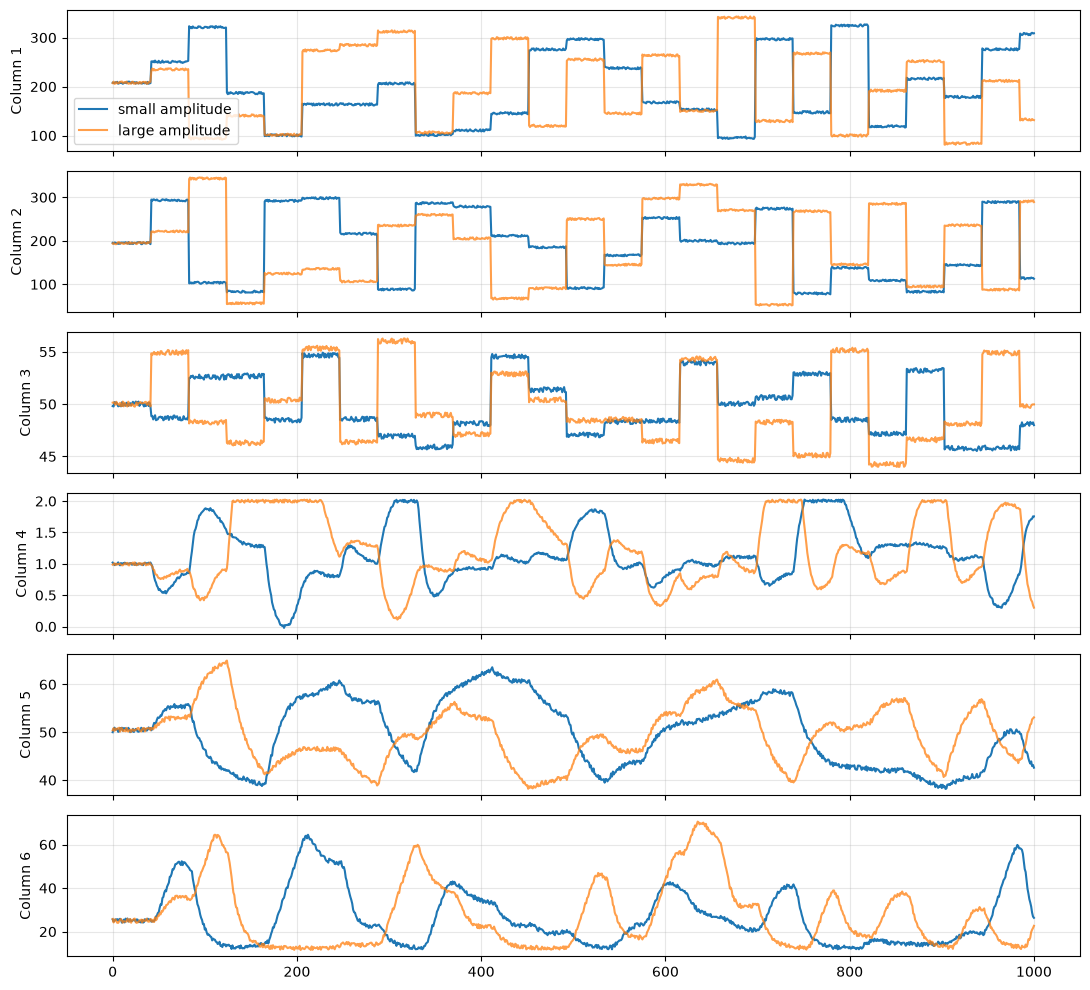

In [27]:
raw_data = io.loadmat("p_dat.mat", squeeze_me=True)
p_dat = raw_data["p_dat"]

small = p_dat[0]
large = p_dat[1]


print(small.shape)  # (1001, 6)
print(large.shape)  # (1001, 6)

fig, axes = plt.subplots(6, 1, figsize=(11, 10), sharex=True)

for col, ax in enumerate(axes):
    ax.plot(small[:, col], label="small amplitude")
    ax.plot(large[:, col], label="large amplitude", alpha=0.75)
    ax.set_ylabel(f"Column {col + 1}")
    ax.grid(True, alpha=0.3)

axes[0].legend()
fig.tight_layout()
plt.show()

The chart above show the input-output data where the first 3 columns being the inputs and the last 3 being the outputs. Below these are split into the training and validation as well as the input and output sets.

In [ ]:
small_train = small[:501, :]
small_val = small[501:, :]

large_train = large[:501, :]
large_val = large[501:, :]

u_small_train = small_train[:, :3]
y_small_train = small_train[:, 3:]

u_large_train = large_train[:, :3]
y_large_train = large_train[:, 3:]

u_small_val = small_val[:, :3]
y_small_val = small_val[:, 3:]

u_large_val = large_val[:, :3]
y_large_val = large_val[:, 3:]